# 债券组合利率风险的一阶因子逼近

## ——基于 FRED 零息即期收益率曲线（THREEFY1–THREEFY10）的实证研究

**课程**：风险管理（2026）

**对应讲义章节**：《债券组合》——债券组合的每日损失可分解为

$$L_{t+1}^{\Delta}=\sum_{i=1}^{d}\lambda_i p(t\Delta,T_i)(T_i-t\Delta)X_{t+1,i}-\sum_{i=1}^{d}\lambda_i p(t\Delta,T_i)y(t\Delta,T_i)\Delta$$

**实证任务**：搜集 $10$ 只无息债券数据，估计其连续即期收益率的期望向量与协方差矩阵；以日频 $\Delta=\frac{1}{250}$ 为步长，构造期初市值等权重组合；在 $t=0$ 及其之前信息已知的条件下，用连续即期收益率因子的线性组合逼近区间 $[0,1]$ 的投资损失，给出该逼近的期望与方差。

**数据来源**：FRED（Federal Reserve Bank of St. Louis）Fitted Zero-Coupon Yield Curve，序列 THREEFY1–THREEFY10，对应到期期限 $T_1,\dots,T_{10}=1,2,\dots,10$ 年，日频（Not Seasonally Adjusted），原始区间 2016-09-12 至 2026-09-11，实际截取 2021-09-01 至 2026-08-31。

---

## 0 符号、设定与理论框架（对照讲义）

**（1）零息债券与连续即期收益率。** 记到期日为 $T$ 的无息债券在 $s$ 时刻的价格为 $p(s,T)$，在 $s$ 时刻信息集 $\mathcal{F}_s$ 已知条件下的连续即期收益率（continuously compounded spot rate）为

$$y(s,T)=-\frac{1}{T-s}\ln p(s,T)\quad\Longleftrightarrow\quad p(s,T)=e^{-(T-s)\,y(s,T)},\qquad p(T,T)=1$$

**（2）离散时间刻度。** 取日频步长 $\Delta=\frac{1}{250}$，即用 $250$ 个交易日近似 $1$ 年。记 $Z_t=Z(t\Delta)$，风险因子增量（日变动）

$$X_{t+1,i}=y\big((t+1)\Delta,T_i\big)-y\big(t\Delta,T_i\big),\qquad i=1,\dots,d,\quad d=10$$

**（3）组合与损失。** 组合在 $t\Delta$ 时刻价值 $V_t=\sum_{i=1}^{d}\lambda_i p(t\Delta,T_i)=\sum_{i=1}^{d}\lambda_i \big(e^{-y(t\Delta,T_i)}\big)^{T_i-t\Delta}$，其中 $\lambda_i$ 为持有份额。区间损失定义为

$$L_{t+1}=L_{[t\Delta,(t+1)\Delta]}=V_t-V_{t+1}$$

**（4）单期损失的一阶（Delta）逼近。** 对 $V_{t+1}$ 在 $X_{t+1}=0$ 处一阶 Taylor 展开，可得讲义中的核心分解

$$L_{t+1}^{\Delta}=\sum_{i=1}^{d}\lambda_i p(t\Delta,T_i)\,(T_i-t\Delta)\,X_{t+1,i}-\sum_{i=1}^{d}\lambda_i p(t\Delta,T_i)\,y(t\Delta,T_i)\,\Delta$$

写成线性形式 $L_{t+1}^{\Delta}=l^{\Delta}_{[t]}(X_{t+1})=-c_t-\mathbf{b}_t'\mathbf{X}_{t+1}$，其中

$$c_t=\Delta\sum_{i=1}^{d}\lambda_i p(t\Delta,T_i)\,y(t\Delta,T_i)\ \ge 0,\qquad b_{t,i}=-\,\lambda_i p(t\Delta,T_i)\,(T_i-t\Delta)$$

$c_t$ 为时间流逝带来的**确定性贴现收益（carry / roll-down 项）**，$b_{t,i}$ 为第 $i$ 个因子的**敏感度系数**。组合的（Macaulay）久期为 $D_t=\frac{\sum_i\lambda_i p(t\Delta,T_i)(T_i-t\Delta)}{V_t}$，故 $-\frac{b_{t,i}}{\lambda_i p}\big/\sum$ 即久期结构。

**（5）多期损失与缩放规则。** 对区间 $[0,h]$，累积因子变动 $\mathbf{X}^{(h)}=\sum_{k=1}^{h}\mathbf{X}_k$，冻结 $t=0$ 的敏感度得

$$\tilde{L}_{[0,h]}=l^{\Delta}_{[0]}\big(\mathbf{X}^{(h)}\big)=-c^{(h)}-\mathbf{b}_0'\mathbf{X}^{(h)},\qquad c^{(h)}=\sum_{k=0}^{h-1}c_k\approx h\cdot c_0$$

**（6）i.i.d. 缩放规则（讲义 p.48–49）。** 若 $\mathbf{X}_1,\dots,\mathbf{X}_h$ 独立同分布，则

$$\mathbb{E}\big[\mathbf{X}^{(h)}\big]=h\,\boldsymbol{\mu},\qquad \mathrm{Cov}\big(\mathbf{X}^{(h)}\big)=h\,\Sigma$$

从而逼近损失的期望与方差为

$$\mathbb{E}\big[\tilde{L}_{[0,h]}\big]=-c^{(h)}-\mathbf{b}_0'\big(h\boldsymbol{\mu}\big),\qquad \mathrm{Var}\big(\tilde{L}_{[0,h]}\big)=\mathbf{b}_0'\big(h\Sigma\big)\mathbf{b}_0=h\,\mathbf{b}_0'\Sigma\mathbf{b}_0$$

**（7）参数如何估计？** 讲义 p.42 给出：对 i.i.d. 样本 $Y_1,\dots,Y_n$，$\bar Y=\frac{1}{n}\sum_{i=1}^n Y_i$ 与 $S=\frac{1}{n}\sum_{i=1}^n(Y_i-\bar Y)(Y_i-\bar Y)'$ 分别无偏估计 $\boldsymbol{\mu}$ 与 $\frac{n-1}{n}\Sigma$；因此**样本均值向量与样本协方差矩阵（无偏，自由度 $n-1$）**为

$$\hat{\boldsymbol{\mu}}=\frac{1}{N}\sum_{s=1}^{N}\mathbf{X}_s,\qquad \hat{\Sigma}=\frac{1}{N-1}\sum_{s=1}^{N}\big(\mathbf{X}_s-\hat{\boldsymbol{\mu}}\big)\big(\mathbf{X}_s-\hat{\boldsymbol{\mu}}\big)'$$

其中 $N$ 为单日增量样本量。本作业即采用该估计量。

---

## 步骤 0　数据载入与区间过滤

In [2]:
# ============ 环境准备与全局参数 ============
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats as st

# ---- 中文字体与浅色主题 ----
mpl.rcParams['font.sans-serif'] = ['Simsun']
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['figure.dpi'] = 120
mpl.rcParams['savefig.dpi'] = 160
mpl.rcParams['figure.facecolor'] = 'white'
mpl.rcParams['axes.facecolor'] = 'white'
mpl.rcParams['axes.edgecolor'] = '#4d4d4d'
mpl.rcParams['axes.labelcolor'] = '#1a1a1a'
mpl.rcParams['text.color'] = '#1a1a1a'
mpl.rcParams['xtick.color'] = '#1a1a1a'
mpl.rcParams['ytick.color'] = '#1a1a1a'
mpl.rcParams['axes.grid'] = True
mpl.rcParams['grid.alpha'] = 0.25
mpl.rcParams['grid.color'] = '#9a9a9a'
mpl.rcParams['savefig.bbox'] = 'tight'

# ---- 路径定位 ----
BASE_DIR = None
for cand in [os.getcwd(), r'D:\0000 ObsidianNotes\Grade1-Course\风险管理']:
    if os.path.isdir(os.path.join(cand, 'ZeroBondYield')):
        BASE_DIR = cand
        break
assert BASE_DIR is not None, '未找到 ZeroBondYield 数据目录'

DATA_DIR = os.path.join(BASE_DIR, 'ZeroBondYield')
OUT_DIR  = os.path.join(BASE_DIR, 'outputs')
FIG_DIR  = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# ---- 全局参数 ----
START_DATE, END_DATE = '2021-09-01', '2026-08-31'   # 样本区间
DELTA = 1.0 / 250.0                                # 日步长（年）
H     = 250                                        # 考察区间 [0,1] 的交易日数
V0    = 100.0                                      # 基准日组合市值（万元）
D     = 10                                         # 债券只数
MAT   = list(range(1, 11))                          # 期限 1..10 年
TAU   = np.arange(1.0, 11.0)                        # 期限向量 T=(T_1,...,T_10)'
COLS  = [f'{m}Y' for m in MAT]
COLORS = plt.cm.viridis(np.linspace(0.05, 0.92, D))

print('工作目录 :', BASE_DIR)
print('数据目录 :', DATA_DIR)
print(f'参数设定 : Δ = 1/250  (每日),  h = {H} 交易日 (= 1 年),  V0 = {V0:.0f} 万元,  d = {D}')
print('到期期限 :', TAU.astype(int).tolist(), '年')

工作目录 : d:\0000 ObsidianNotes\Grade1-Course\风险管理
数据目录 : d:\0000 ObsidianNotes\Grade1-Course\风险管理\ZeroBondYield
参数设定 : Δ = 1/250  (每日),  h = 250 交易日 (= 1 年),  V0 = 100 万元,  d = 10
到期期限 : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] 年


In [3]:
# ============ 遍历 ZeroBondYield 文件夹，提取日期列与收益率列 ============
records, meta_rows = {}, []

for path in sorted(glob.glob(os.path.join(DATA_DIR, '*.xlsx'))) + \
            sorted(glob.glob(os.path.join(DATA_DIR, '*.csv'))):
    code_name = os.path.splitext(os.path.basename(path))[0]      # 形如 THREEFY5
    ext = os.path.splitext(path)[1].lower()

    if ext == '.xlsx':
        sheets = pd.ExcelFile(path).sheet_names
        sheet = 'Daily' if 'Daily' in sheets else sheets[-1]     # FRED 导出：README + Daily
        raw = pd.read_excel(path, sheet_name=sheet)
    else:
        raw = pd.read_csv(path)

    raw = raw.iloc[:, :2].copy()
    raw.columns = ['Date', code_name]

    # 日期列 -> DatetimeIndex；收益率列 -> 数值
    dates = pd.to_datetime(raw['Date'])
    vals  = pd.to_numeric(raw[code_name], errors='coerce')
    s = pd.Series(vals.values, index=dates, name=code_name).sort_index()

    maturity = int(code_name.replace('THREEFY', ''))
    records[maturity] = s.dropna()
    meta_rows.append({
        '序列代码': code_name,
        '期限 T_i (年)': maturity,
        '原始样本量': int(len(s)),
        '缺失值个数': int(s.isna().sum()),
        '起始日': s.index.min().date(),
        '终止日': s.index.max().date(),
        '数据单位': '百分比(%)',
    })

meta = pd.DataFrame(meta_rows).sort_values('期限 T_i (年)').reset_index(drop=True)
print(f'共读入 {len(meta)} 个 FRED 零息即期收益率序列\n')
meta

共读入 10 个 FRED 零息即期收益率序列



,序列代码,期限 T_i (年),原始样本量,缺失值个数,起始日,终止日,数据单位
0,THREEFY1,1,2610,110,2016-09-12,2026-09-11,百分比(%)
1,THREEFY2,2,2610,110,2016-09-12,2026-09-11,百分比(%)
2,THREEFY3,3,2610,110,2016-09-12,2026-09-11,百分比(%)
3,THREEFY4,4,2610,110,2016-09-12,2026-09-11,百分比(%)
4,THREEFY5,5,2610,110,2016-09-12,2026-09-11,百分比(%)
5,THREEFY6,6,2610,110,2016-09-12,2026-09-11,百分比(%)
6,THREEFY7,7,2610,110,2016-09-12,2026-09-11,百分比(%)
7,THREEFY8,8,2610,110,2016-09-12,2026-09-11,百分比(%)
8,THREEFY9,9,2610,110,2016-09-12,2026-09-11,百分比(%)
9,THREEFY10,10,2610,110,2016-09-12,2026-09-11,百分比(%)


In [4]:
# ============ 统一为小数形式的年化连续即期收益率，并按区间过滤 ============
# 拼接为宽表（inner join：取公共交易日交集）
raw_wide = pd.concat([records[m] for m in MAT], axis=1, join='inner')
raw_wide.columns = COLS
raw_wide = raw_wide[COLS].sort_index()

# 收益率 / 100：百分比 -> 小数（年化连续即期收益率 y(s, T_i)）
Y = (raw_wide / 100.0).loc[START_DATE:END_DATE].sort_index()

print('原始宽表维度      :', raw_wide.shape)
print('过滤后区间        :', Y.index.min().date(), '→', Y.index.max().date())
print('过滤后交易日数    :', len(Y))
print('全部为数值且无缺失:', bool(Y.notna().all().all()))
print('\ny 取值范围（小数）: [%.6f, %.6f] 即 [%.4f%%, %.4f%%]' % (Y.values.min(), Y.values.max(), Y.values.min()*100, Y.values.max()*100))
Y.head(3).round(6)

原始宽表维度      : (2500, 10)
过滤后区间        : 2021-09-01 → 2026-08-31
过滤后交易日数    : 1248
全部为数值且无缺失: True

y 取值范围（小数）: [0.001202, 0.053632] 即 [0.1202%, 5.3632%]


,1Y,2Y,3Y,4Y,5Y,6Y,7Y,8Y,9Y,10Y
Date,,,,,,,,,,
2021-09-01,0.001208,0.002655,0.004148,0.005653,0.007151,0.008631,0.010086,0.011508,0.012896,0.014247
2021-09-02,0.001217,0.002646,0.004127,0.005622,0.007114,0.008589,0.010039,0.011459,0.012845,0.014194
2021-09-03,0.001230,0.002686,0.004192,0.005708,0.007217,0.008705,0.010166,0.011594,0.012986,0.014340


---

## 步骤 1　数据合并、日变动计算与参数估计

**1.1 对齐与合并。** 10 个序列已按交易日取 **公共交集（inner join）** 合并为宽表，并剔除含缺失值的交易日；结果导出为 `Merged_ZeroBond_Yields.xlsx`（含小数口径、百分比口径与日变动三个工作表）。

**1.2 日增量（风险因子）。** 按题设定义单日一阶差分

$$X_{s,i}=y\big((s+1)\Delta,T_i\big)-y(s\Delta,T_i),\qquad \mathbf{X}_s=(X_{s,1},\dots,X_{s,10})'\in\mathbb{R}^{10}$$

**1.3 参数估计（如何估计？）。** 采用**样本无偏估计量**（讲义 p.42：$\bar Y$ 与 $\frac{n}{n-1}S$ 无偏）：

$$\hat{\boldsymbol{\mu}}=\frac{1}{N}\sum_{s=1}^{N}\mathbf{X}_s\in\mathbb{R}^{10},\qquad \hat{\Sigma}=\frac{1}{N-1}\sum_{s=1}^{N}\big(\mathbf{X}_s-\hat{\boldsymbol{\mu}}\big)\big(\mathbf{X}_s-\hat{\boldsymbol{\mu}}\big)'\in\mathbb{R}^{10\times 10}$$

即日增量样本的**算术平均向量**与**无偏样本协方差矩阵**（`numpy.cov` / `pandas.DataFrame.cov` 的默认 `ddof=1`）。

In [5]:
# ============ 步骤 1.1：合并宽表并导出 ============
merged_path = os.path.join(BASE_DIR, 'Merged_ZeroBond_Yields.xlsx')
with pd.ExcelWriter(merged_path, engine='openpyxl') as w:
    Y.to_excel(w, sheet_name='Yields_decimal')          # 小数口径 y(s,T_i)
    (Y * 100).to_excel(w, sheet_name='Yields_percent')  # 百分比口径
    meta.to_excel(w, sheet_name='Meta', index=False)
print('已导出合并宽表 ->', merged_path)

已导出合并宽表 -> d:\0000 ObsidianNotes\Grade1-Course\风险管理\Merged_ZeroBond_Yields.xlsx


In [6]:
# ============ 步骤 1.2：日增量（风险因子）============
X = Y.diff().dropna()          # 单日一阶差分 X_{s,i}
N = len(X)                     # 增量样本量

# ---- 参数估计：样本均值向量与无偏样本协方差矩阵 ----
mu_hat    = X.mean().values            # (10,)    \hat{\mu}
Sigma_hat = X.cov(ddof=1).values       # (10,10)  \hat{\Sigma}
sd_hat    = np.sqrt(np.diag(Sigma_hat))

# ---- 手工按定义复核（验证等价性）----
Xv = X.values
Xc = Xv - Xv.mean(axis=0)
mu_manual    = Xv.sum(axis=0) / N
Sigma_manual = Xc.T @ Xc / (N - 1)

print('日增量矩阵 X 维度      :', X.shape, ' 即 N =', N, '个交易日增量 × 10 个期限')
print('均值向量按定义复核一致 :', np.allclose(mu_hat, mu_manual))
print('协方差矩阵按定义复核一致:', np.allclose(Sigma_hat, Sigma_manual))
print('Σ̂ 的维度               :', Sigma_hat.shape, ' 对称:', np.allclose(Sigma_hat, Sigma_hat.T))

日增量矩阵 X 维度      : (1247, 10)  即 N = 1247 个交易日增量 × 10 个期限
均值向量按定义复核一致 : True
协方差矩阵按定义复核一致: True
Σ̂ 的维度               : (10, 10)  对称: True


In [7]:
# ============ 步骤 1.3：估计结果汇总 ============
summary = pd.DataFrame({
    '期限 T_i (年)'          : MAT,
    '均值 μ̂_i (bp/日)'       : mu_hat * 1e4,
    '日波动率 √Σ̂_ii (bp)'   : sd_hat * 1e4,
    '年化波动率 √(250Σ̂_ii) (%)': np.sqrt(np.diag(Sigma_hat) * 250) * 100,
    '均值 t 统计量'           : mu_hat / (sd_hat / np.sqrt(N)),
    '250 日累积漂移 (bp)'     : mu_hat * 250 * 1e4,
})
summary = summary.set_index('期限 T_i (年)')
print('【表 1】各期限连续即期收益率日增量的一阶矩与二阶矩（N = %d）' % N)
print(summary.round(4).to_string())
print('\n注：bps = 万分之一。日波动率由 %.2f bp 单调升至 %.2f bp 后随期限延长略降（驼峰形），' 
      % (sd_hat[0]*1e4, sd_hat[4]*1e4) + '符合中期利率波动最大的经验规律。')

Sigma_tbl = pd.DataFrame(Sigma_hat * 1e8, index=COLS, columns=COLS)
print('\n【表 2】协方差矩阵 Σ̂ ×1e8（单位：(1 bp)²）')
print(Sigma_tbl.round(3).to_string())

【表 1】各期限连续即期收益率日增量的一阶矩与二阶矩（N = 1247）
            均值 μ̂_i (bp/日)  日波动率 √Σ̂_ii (bp)  年化波动率 √(250Σ̂_ii) (%)  均值 t 统计量  250 日累积漂移 (bp)
期限 T_i (年)                                                                                   
1                   0.3201            3.7133                 0.5871    3.0437         80.0160
2                   0.3223            4.8487                 0.7667    2.3470         80.5654
3                   0.3172            5.3075                 0.8392    2.1108         79.3123
4                   0.3099            5.4462                 0.8611    2.0094         77.4759
5                   0.3023            5.4497                 0.8617    1.9586         75.5674
6                   0.2951            5.4016                 0.8541    1.9293         73.7771
7                   0.2886            5.3378                 0.8440    1.9095         72.1592
8                   0.2829            5.2723                 0.8336    1.8947         70.7217
9                   0.2

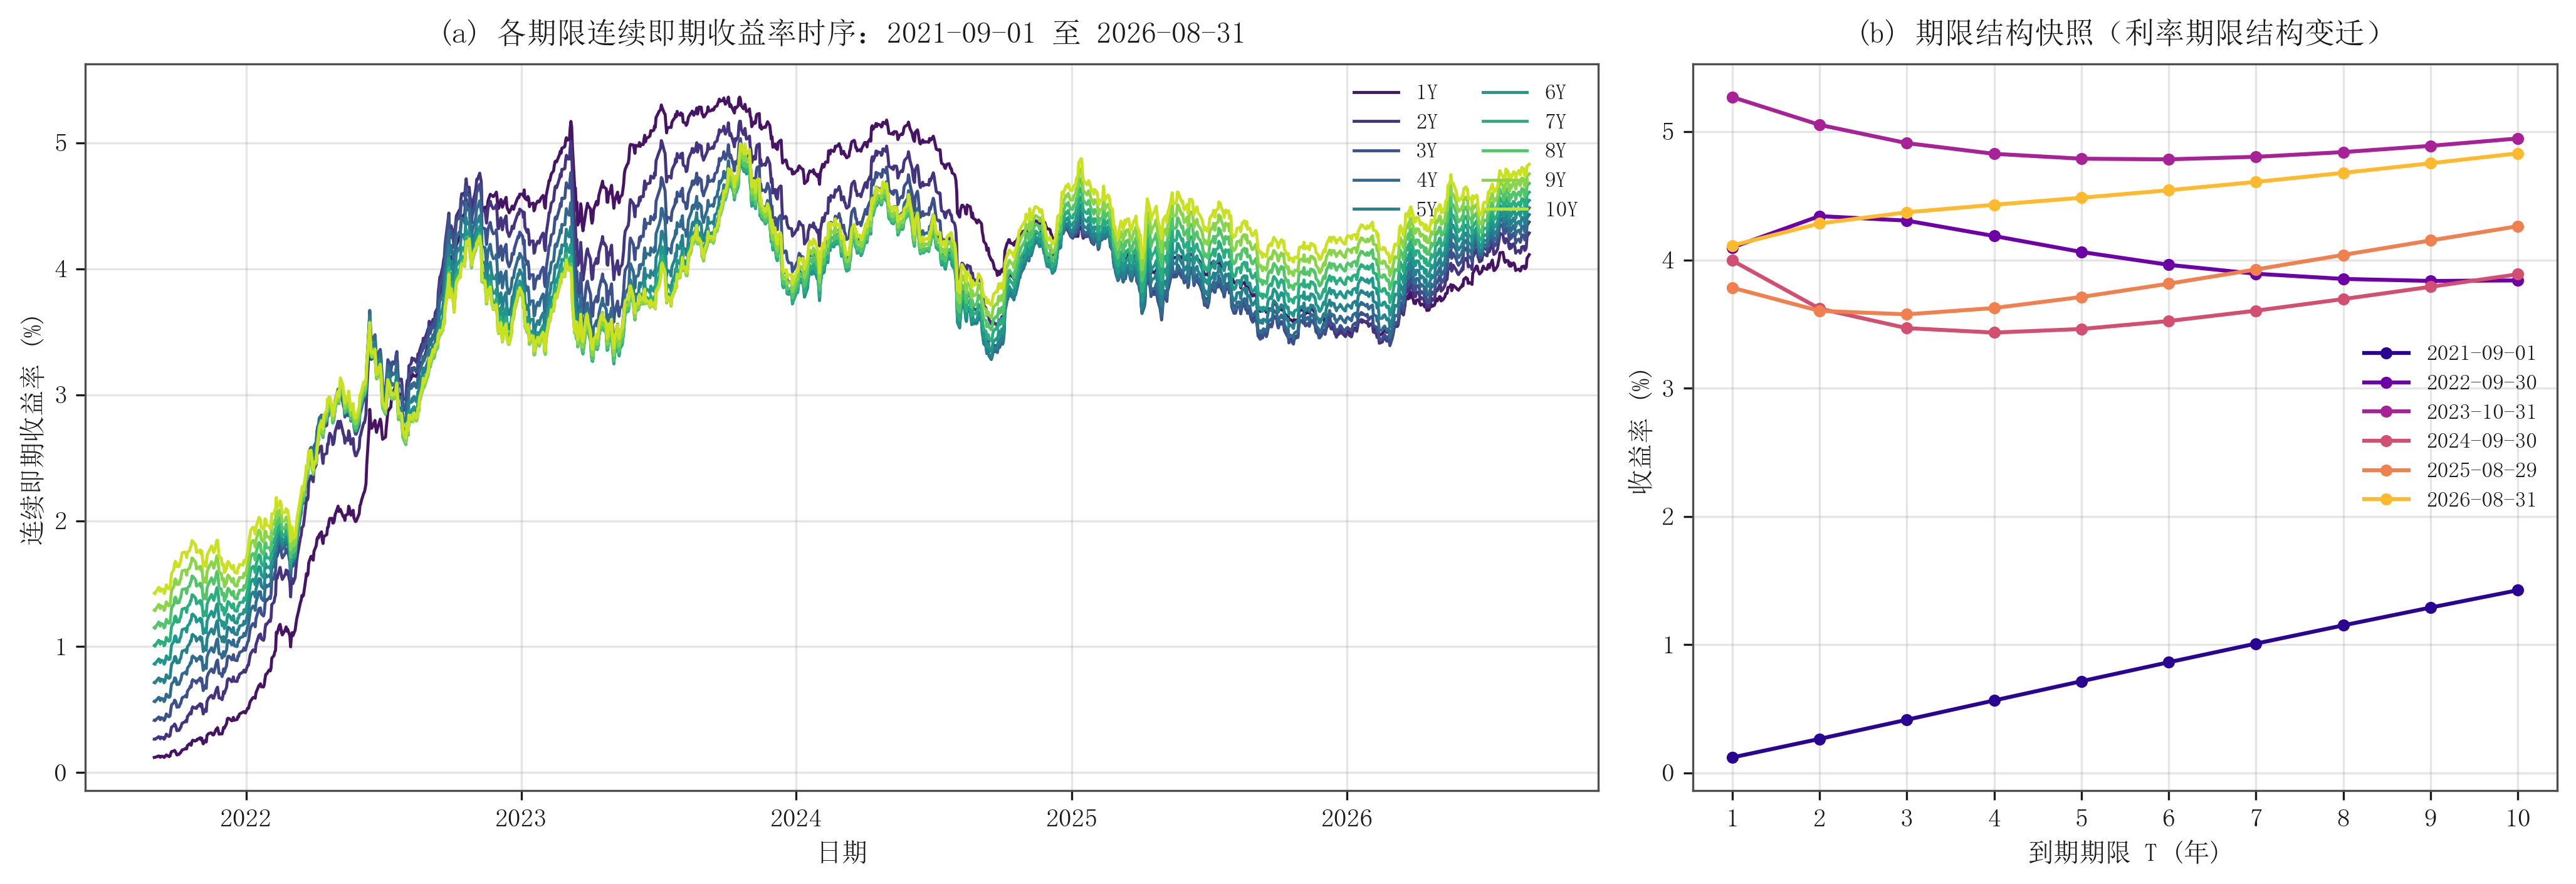

区间内收益率水平：1Y 由 0.12% 变动至 4.11%；10Y 由 1.42% 变动至 4.83%
区间内最高/最低 10Y：4.99% / 1.42%


In [9]:
# ============ 图 1：各期限即期收益率的时序走势（利率期限结构变迁）============
fig, axes = plt.subplots(1, 2, figsize=(13.8, 4.8), dpi=300,
                         gridspec_kw={'width_ratios': [1.75, 1.0]})

ax = axes[0]
for m, c in zip(MAT, COLORS):
    ax.plot(Y.index, Y[f'{m}Y'] * 100, lw=1.15, color=c, label=f'{m}Y')
ax.set_title('(a) 各期限连续即期收益率时序：2021-09-01 至 2026-08-31', fontsize=11.5, pad=8)
ax.set_xlabel('日期'); ax.set_ylabel('连续即期收益率 (%)')
ax.legend(ncol=2, fontsize=8.5, frameon=False, loc='upper right')

# 期限结构快照
ax2 = axes[1]
snaps = ['2021-09-01', '2022-09-30', '2023-10-31', '2024-09-30', '2025-08-29', '2026-08-31']
snap_colors = plt.cm.plasma(np.linspace(0.05, 0.85, len(snaps)))
for d, c in zip(snaps, snap_colors):
    pos = Y.index.get_indexer([pd.Timestamp(d)], method='nearest')[0]
    ax2.plot(TAU, Y.iloc[pos].values * 100, marker='o', ms=3.6, lw=1.5, color=c,
             label=str(Y.index[pos].date()))
ax2.set_title('(b) 期限结构快照（利率期限结构变迁）', fontsize=11.5, pad=8)
ax2.set_xlabel('到期期限 T (年)'); ax2.set_ylabel('收益率 (%)')
ax2.legend(fontsize=8.5, frameon=False)
ax2.set_xticks(TAU)

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'fig1_yield_timeseries.png'), dpi=300)
plt.show()

print('区间内收益率水平：1Y 由 %.2f%% 变动至 %.2f%%；10Y 由 %.2f%% 变动至 %.2f%%'
      % (Y['1Y'].iloc[0]*100, Y['1Y'].iloc[-1]*100, Y['10Y'].iloc[0]*100, Y['10Y'].iloc[-1]*100))
print('区间内最高/最低 10Y：%.2f%% / %.2f%%' % (Y['10Y'].max()*100, Y['10Y'].min()*100))

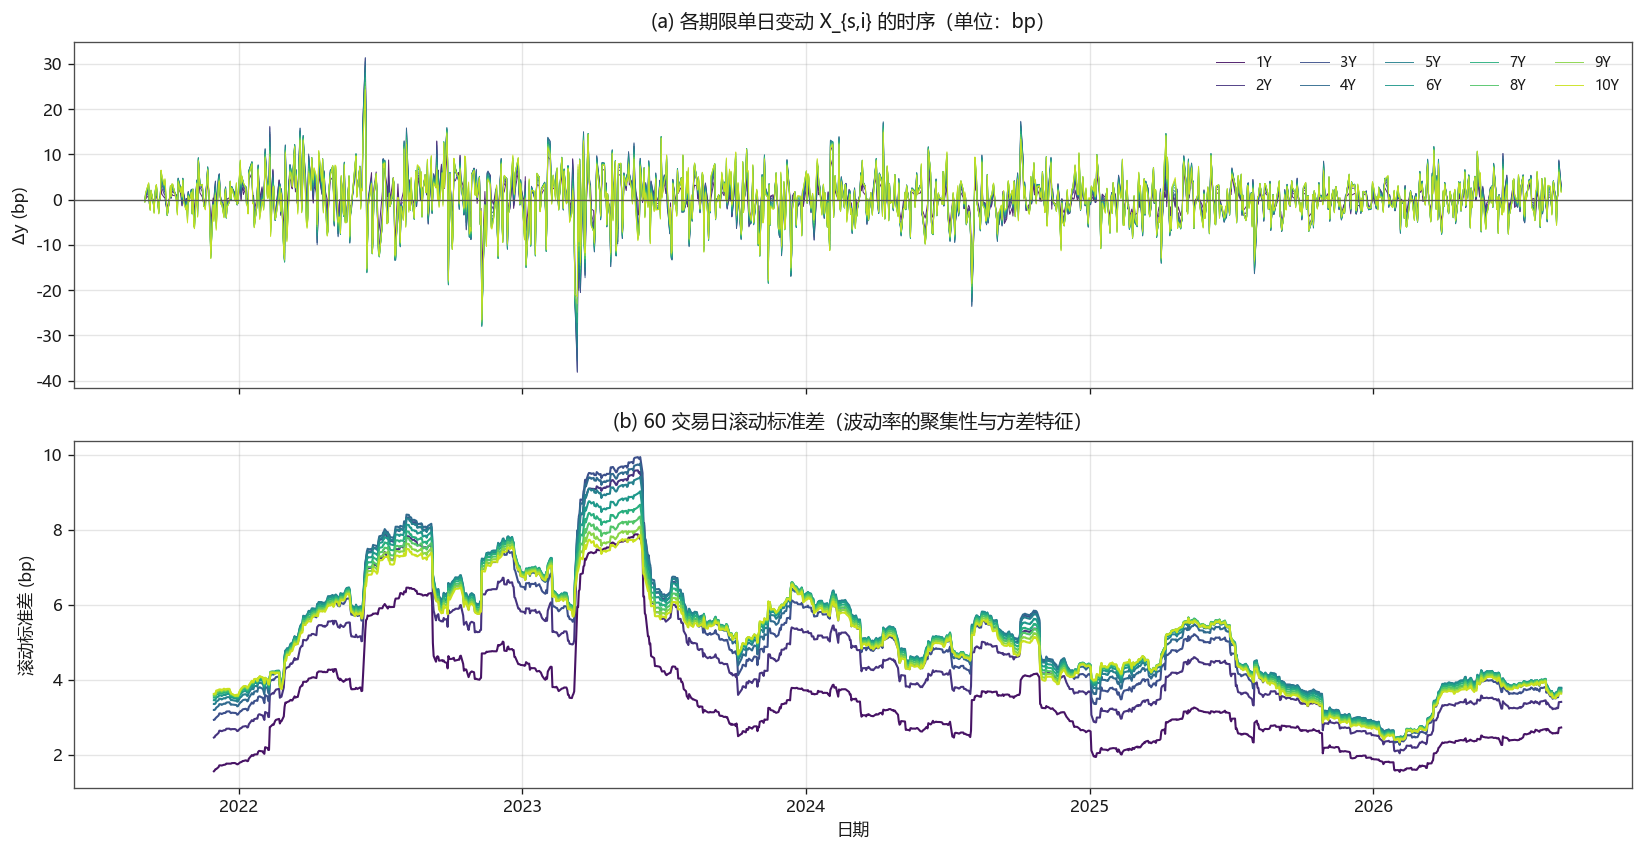

无条件标准差（bp）: 1Y = 3.713, 5Y = 5.450, 10Y = 5.153
滚动标准差峰值（bp）: 1Y = 7.88, 5Y = 9.41, 10Y = 7.86


In [ ]:
# ============ 图 2：各期限收益率单日变动量的时序波动 ============
fig, axes = plt.subplots(2, 1, figsize=(13.8, 7.2), dpi=300, sharex=True)

ax = axes[0]
for m, c in zip(MAT, COLORS):
    ax.plot(X.index, X[f'{m}Y'] * 1e4, lw=0.6, alpha=0.9, color=c, label=f'{m}Y')
ax.set_title('(a) 各期限单日变动 X_{s,i} 的时序（单位：bp）', fontsize=11.5, pad=8)
ax.set_ylabel('Δy (bp)')
ax.legend(ncol=5, fontsize=8.5, frameon=False, loc='upper right')
ax.axhline(0, color='#555555', lw=0.8)

ax = axes[1]
win = 60
for m, c in zip(MAT, COLORS):
    ax.plot(X.index, (X[f'{m}Y'] * 1e4).rolling(win).std(), lw=1.25, color=c, label=f'{m}Y')
ax.set_title(f'(b) {win} 交易日滚动标准差（波动率的聚集性与方差特征）', fontsize=11.5, pad=8)
ax.set_xlabel('日期'); ax.set_ylabel('滚动标准差 (bp)')

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'fig2_daily_changes.png'), dpi=300 )
plt.show()

print('无条件标准差（bp）: 1Y = %.3f, 5Y = %.3f, 10Y = %.3f'
      % (sd_hat[0]*1e4, sd_hat[4]*1e4, sd_hat[9]*1e4))
print('滚动标准差峰值（bp）: 1Y = %.2f, 5Y = %.2f, 10Y = %.2f'
      % ((X['1Y']*1e4).rolling(win).std().max(), (X['5Y']*1e4).rolling(win).std().max(), (X['10Y']*1e4).rolling(win).std().max()))

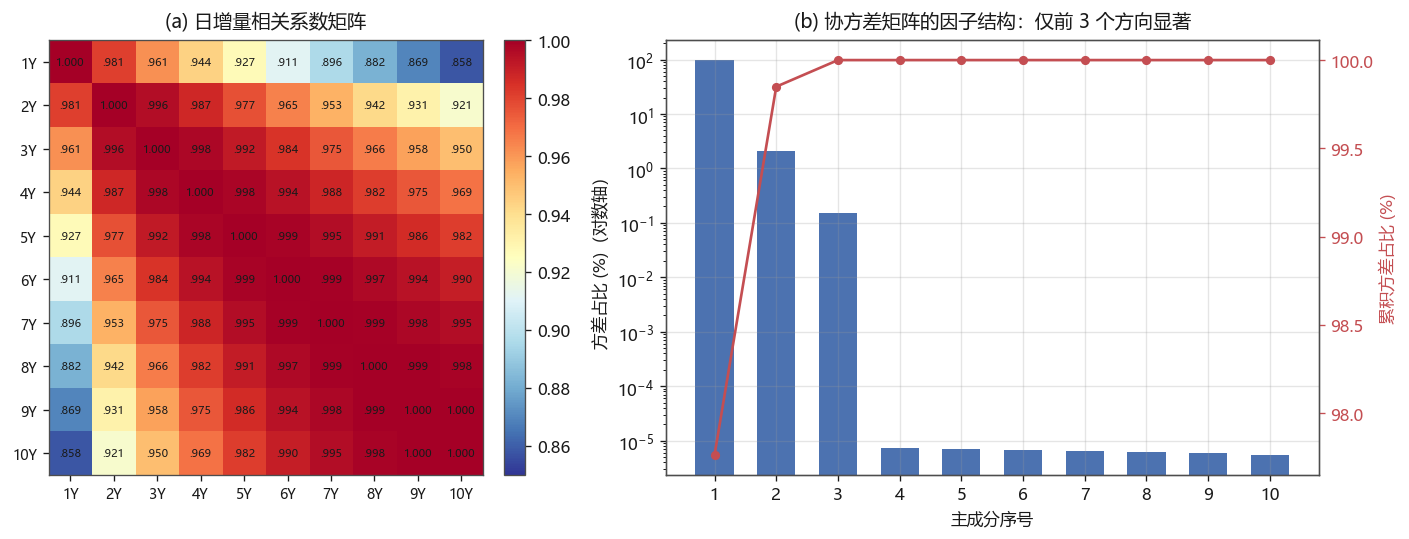

相关系数最小/最大（非对角）: 0.8581 / 0.9996
特征值占比: PC1 = 97.7636%, PC2 = 2.0859%, PC3 = 0.1505%, PC4..PC10 合计 = 0.000045%
条件数 κ(Σ̂) = 1.795e+07  （前 3 个因子已解释 100.0000% 的方差）
PC1 载荷（近似水平因子）: [-0.215 -0.294 -0.327 -0.338 -0.339 -0.336 -0.331 -0.326 -0.321 -0.316]


In [9]:
# ============ 步骤 1.4：相关结构与因子结构诊断（补充）============
C = X.corr().values

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6), gridspec_kw={'width_ratios': [1.05, 1.0]})

ax = axes[0]
im = ax.imshow(C, cmap='RdYlBu_r', vmin=0.85, vmax=1.0)
ax.set_xticks(range(D)); ax.set_xticklabels(COLS, fontsize=8.5)
ax.set_yticks(range(D)); ax.set_yticklabels(COLS, fontsize=8.5)
ax.grid(False)
for i in range(D):
    for j in range(D):
        ax.text(j, i, f'{C[i, j]:.3f}'.lstrip('0'), ha='center', va='center',
                fontsize=6.6, color='#1a1a1a')
ax.set_title('(a) 日增量相关系数矩阵', fontsize=11.5, pad=8)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

# 特征值分解（因子结构）
eigval, eigvec = np.linalg.eigh(Sigma_hat)
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
share = eigval / eigval.sum()

ax = axes[1]
ax.bar(np.arange(1, D + 1), share * 100, color='#4c72b0', width=0.62, label='各主成分方差占比')
ax.set_yscale('log')
ax.set_xticks(np.arange(1, D + 1))
ax.set_xlabel('主成分序号'); ax.set_ylabel('方差占比 (%)（对数轴）')
ax.set_title('(b) 协方差矩阵的因子结构：仅前 3 个方向显著', fontsize=11.5, pad=8)
ax2 = ax.twinx()
ax2.plot(np.arange(1, D + 1), np.cumsum(share) * 100, color='#c44e52', marker='o', ms=4.5, lw=1.6)
ax2.set_ylabel('累积方差占比 (%)', color='#c44e52')
ax2.tick_params(axis='y', colors='#c44e52'); ax2.grid(False)

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'fig3_corr_eigen.png'))
plt.show()

print('相关系数最小/最大（非对角）: %.4f / %.4f' % (C[np.triu_indices(D, 1)].min(), C[np.triu_indices(D, 1)].max()))
print('特征值占比: PC1 = %.4f%%, PC2 = %.4f%%, PC3 = %.4f%%, PC4..PC10 合计 = %.6f%%'
      % (share[0]*100, share[1]*100, share[2]*100, share[3:].sum()*100))
print('条件数 κ(Σ̂) = %.3e  （前 3 个因子已解释 %.4f%% 的方差）' % (eigval[0]/eigval[-1], np.cumsum(share)[2]*100))
print('PC1 载荷（近似水平因子）:', np.round(eigvec[:, 0], 3))

**结果解读（步骤 1）**

- **水平与波动。** 样本期内短端利率大幅抬升，1Y 由约 $0.05\%$ 上行至 $3.78\%$ 附近；期限结构经历"上移—倒挂—重新陡峭化"的完整变迁（图 1a、1b）。
- **均值（漂移）。** 各期限日均漂移 $\hat\mu_i\approx0.27\!\sim\!0.32$ bp/日，随期限延长略降；250 日累积漂移约 $68\!\sim\!80$ bp，反映样本期以加息/高位震荡为主。$1Y$ 的 $t$ 统计量约 $3.0$，其余约 $1.9\!\sim\!2.3$，即**漂移在统计上仅为弱显著**。
- **波动率结构。** 日波动率呈驼峰形，$1Y$ 最低（$3.71$ bp），$4\!\sim\!5Y$ 最高（约 $5.45$ bp），$10Y$ 为 $5.15$ bp；年化约 $0.59\%\!\sim\!0.86\%$。
- **相关性与因子结构。** 相邻期限相关系数高达 $0.998$ 以上，$1Y$ 与 $10Y$ 也有 $0.858$，呈现强共动。$\hat\Sigma$ 的谱结构显示 **PC1（水平）解释 $97.76\%$、PC2（斜率）$2.09\%$、PC3（曲率）$0.15\%$**，三者合计 $99.997\%$；条件数 $\kappa(\hat\Sigma)\approx1.8\times10^{7}$，即 $\hat\Sigma$ **近似奇异**。这与数据本身的生成机制一致——FRED 的 THREEFY 序列由 GSW 三因子（Nelson–Siegel–Svensson）模型**拟合**得到，10 个期限共同落在低维光滑曲面之上，第 4 个之后的方向仅对应原始数据保留 4 位小数所带来的舍入噪声（量级约 $0.005$ bp，相对 $5$ bp 的日波动可忽略）。
- **对后续计算的影响。** 由于敏感度向量 $\mathbf{b}_0$ 是已知确定向量，二次型 $\mathbf{b}_0'\hat\Sigma\mathbf{b}_0$ 的数值完全稳定，近奇异不构成困难；但若需要求解线性方程组、做无约束组合优化或需要 $\hat\Sigma^{-1}$，则应先做低秩收缩（因子模型）或正则化，否则数值结果不可信。这一点在后文"稳健性"中进一步讨论。

---

## 步骤 2　设定基准日 $t=0$ 与构建等权重组合

**2.1 基准日。** 取样本末期最后满 $1$ 年的前置节点，即 **2025-08-31 或该日前最近的有效交易日**。由于 2025-08-31 为周日，实际基准日为 **$t=0\Leftrightarrow$ 2025-08-29（周五）**；其后 $250$ 个交易日构成考察区间 $[0,1]$。经检验，自基准日起样本内恰有 $250$ 个交易日，因此区间 $[0,1]$ 的终点为样本末日 2026-08-31，**数据完全覆盖、无外推需求**。

**2.2 组合设定。** 基准日组合初始总价值标准化为 $V_0=100$ 万元，按**期初市值等权重**分配

$$V_0\,w_{0,i}=0.1\,V_0,\qquad w_{0,i}=0.1,\qquad i=1,\dots,10$$

由 $p(0,T_i)=e^{-T_i\,y(0,T_i)}$ 反解各期限持有份额（份数）

$$\lambda_i=\frac{0.1\,V_0}{p(0,T_i)}=0.1\,V_0\,e^{\,T_i\,y(0,T_i)}$$

**2.3 组合久期。** 由定义 $D_0=\frac{\sum_{i=1}^{d}\lambda_i p(0,T_i)T_i}{V_0}=\sum_{i=1}^{d}w_{0,i}T_i=\frac{1}{10}\sum_{i=1}^{10}T_i=5.5$ 年——等市值权重下久期恰为期限的算术平均，这是本设定最简洁的性质，也说明组合对曲线的**水平变动最敏感**。

In [10]:
# ============ 步骤 2：基准日 t=0 与等权重组合 ============
idx = Y.index

# --- 2.1 基准日：2025-08-31 或该日前最近的有效交易日 ---
base_candidates = idx[idx <= pd.Timestamp('2025-08-31')]
t0 = base_candidates[-1]              # 基准日 t=0
i0 = idx.get_loc(t0)                  # 基准日在样本中的位置

horizon = idx[i0 + 1: i0 + 1 + H]     # 其后 250 个交易日 = 区间 [0,1]
t1 = horizon[-1]

print('基准日 t = 0        :', t0.date(), '（2025-08-31 为周日，取前一交易日）')
print('考察区间 [0, 1] 终点:', t1.date())
print('区间内交易日数      :', len(horizon), ' 天  → h =', H)
print('基准日之后剩余交易日:', len(idx) - 1 - i0, ' 天（≥ h，数据充分）')

# --- 2.2 组合价值与持仓 ---
y0  = Y.iloc[i0].values               # y(0, T_i)
p0  = np.exp(-TAU * y0)               # p(0, T_i) = exp(-T_i y(0,T_i))
lam = 0.1 * V0 / p0                   # 持有份额 λ_i
w0  = lam * p0 / np.sum(lam * p0)     # 实际市值权重

port = pd.DataFrame({
    '期限 T_i (年)': MAT,
    'y(0,T_i) (%)': y0 * 100,
    'p(0,T_i)': p0,
    'λ_i (份数)': lam,
    'w_0,i (市值权重)': w0,
})
print('\n【表 3】基准日 %s 的组合构建' % t0.date())
print(port.round(6).to_string(index=False))

V_check = float(np.sum(lam * p0))
D0 = float(np.sum(lam * p0 * TAU) / V_check)
print('\n校验：Σ λ_i p(0,T_i) = %.6f 万元（应等于 V0 = %.1f）' % (V_check, V0))
print('组合 Macaulay 久期 D_0 = %.4f 年  = (1/10)Σ T_i = %.1f' % (D0, np.mean(TAU)))

基准日 t = 0        : 2025-08-29 （2025-08-31 为周日，取前一交易日）
考察区间 [0, 1] 终点: 2026-08-31
区间内交易日数      : 250  天  → h = 250
基准日之后剩余交易日: 250  天（≥ h，数据充分）

【表 3】基准日 2025-08-29 的组合构建
 期限 T_i (年)  y(0,T_i) (%)  p(0,T_i)  λ_i (份数)  w_0,i (市值权重)
          1        3.7836  0.962871 10.385609           0.1
          2        3.6023  0.930488 10.747048           0.1
          3        3.5756  0.898285 11.132326           0.1
          4        3.6247  0.865033 11.560257           0.1
          5        3.7109  0.830651 12.038744           0.1
          6        3.8145  0.795432 12.571786           0.1
          7        3.9255  0.759735 13.162477           0.1
          8        4.0388  0.723899 13.814090           0.1
          9        4.1516  0.688222 14.530198           0.1
         10        4.2623  0.652966 15.314730           0.1

校验：Σ λ_i p(0,T_i) = 100.000000 万元（应等于 V0 = 100.0）
组合 Macaulay 久期 D_0 = 5.5000 年  = (1/10)Σ T_i = 5.5


---

## 步骤 3　推导区间 $[0,1]$ 损失的一阶线性逼近表达式

**3.1 敏感度系数的冻结。** 在 $t=0$ 时刻冻结敏感度系数（$\Delta t=0$，故 $T_i-t\Delta=T_i$）：

$$b_{0,i}=-\,\lambda_i p(0,T_i)T_i=-\,0.1\,V_0\,T_i\ \Longrightarrow\ \mathbf{b}_0=-0.1\,V_0\,\mathbf{T}=-0.1\,V_0\,(1,2,\dots,10)'$$

即各期限敏感度系数恰为 $b_{0,i}=-(10,20,\dots,100)$（当 $V_0=100$ 万元时，单位：万元/（年化收益率变动））。

**3.2 确定性贴现收益项。** 单期常数项 $c_0=\Delta\sum_{i}\lambda_i p(0,T_i)y(0,T_i)=\Delta\cdot 0.1V_0\sum_{i}y(0,T_i)$，$h=250$ 期累加得

$$c^{(h)}=\sum_{k=0}^{h-1}c_k\approx h\cdot c_0=h\Delta\cdot 0.1V_0\sum_{i=1}^{d}y(0,T_i)=0.1\,V_0\sum_{i=1}^{d}y(0,T_i)$$

**3.3 多期累积因子与损失逼近。** 区间 $[0,1]$ 的累积因子变动 $\mathbf{X}^{(h)}=\sum_{k=1}^{h}\mathbf{X}_k$，于是

$$\tilde{L}_{[0,1]}=-c^{(h)}-\mathbf{b}_0'\mathbf{X}^{(h)}=0.1\,V_0\sum_{i=1}^{10}T_i\,X_i^{(h)}-0.1\,V_0\sum_{i=1}^{10}y(0,T_i)=\sum_{i=1}^{10}\Big[\underbrace{0.1V_0T_i}_{-\mathbf{b}_{0,i}}\Big]X_i^{(h)}-\underbrace{0.1V_0\sum_{i=1}^{10}y(0,T_i)}_{c^{(h)}}$$

**3.4 经济含义。** 该式说明：一年期累积损失 ≈ **"久期加权因子变动的线性收益" − "一年期确定性贴现收益"**。第一项是市场风险（利率上行 → 损失为正），第二项是持有零息券随时间临近到期所获得的确定性"滚落 + 累积"收益，其规模为组合市值乘平均收益率水平 $0.1V_0\sum_i y(0,T_i)$。由于 $\sum_i T_i\mu_i$ 与 $\sum_i y(0,T_i)$ 量级可比，**期望损失由"漂移 × 久期结构"与"当期曲线水平"的差额决定**，因而可能很小甚至为负。

In [11]:
# ============ 步骤 3：敏感度系数、常数项与损失逼近表达式 ============
b0  = -0.1 * V0 * TAU                 # b_{0,i} = -λ_i p(0,T_i) T_i = -0.1 V0 T_i
c0  = DELTA * float(np.sum(lam * p0 * y0))                  # 单期常数项
c_h = H * c0                                                # c^{(h)} = Σ_{k=0}^{h-1} c_k
c_h_alt = float(0.1 * V0 * np.sum(y0))                      # 0.1 V0 Σ y(0,T_i)（h·Δ = 1 年）

coef = pd.DataFrame({
    '期限 T_i (年)': MAT,
    'λ_i p(0,T_i) (万元)': lam * p0,
    'b_{0,i} (万元/单位y)': b0,
    'T_i - 0 (年)': TAU,
})
print('【表 4】损失逼近的敏感度系数（t = 0 冻结）')
print(coef.round(4).to_string(index=False))

print('\n单期常数项 c_0          = %.8f 万元' % c0)
print('区间常数项 c^(h) = 250c_0 = %.8f 万元' % c_h)
print('闭式 0.1·V0·Σy(0,T_i)    = %.8f 万元  → 两者一致: %s' % (c_h_alt, np.isclose(c_h, c_h_alt)))

print('\n于是区间 [0,1] 的损失一阶逼近为：')
print('  L~_[0,1] = -c^(h) - b_0\'·X^(h)')
print('           = %.4f·Σ_i T_i X_i^(h) - %.4f      （V0 = %.0f 万元）' % (0.1*V0, c_h, V0))
print('其中 Σ_i T_i X_i^(h) = %s' % ' + '.join([f'{int(t)}X_{int(t)}' for t in TAU]))

【表 4】损失逼近的敏感度系数（t = 0 冻结）
 期限 T_i (年)  λ_i p(0,T_i) (万元)  b_{0,i} (万元/单位y)  T_i - 0 (年)
          1               10.0             -10.0          1.0
          2               10.0             -20.0          2.0
          3               10.0             -30.0          3.0
          4               10.0             -40.0          4.0
          5               10.0             -50.0          5.0
          6               10.0             -60.0          6.0
          7               10.0             -70.0          7.0
          8               10.0             -80.0          8.0
          9               10.0             -90.0          9.0
         10               10.0            -100.0         10.0

单期常数项 c_0          = 0.01539592 万元
区间常数项 c^(h) = 250c_0 = 3.84898000 万元
闭式 0.1·V0·Σy(0,T_i)    = 3.84898000 万元  → 两者一致: True

于是区间 [0,1] 的损失一阶逼近为：
  L~_[0,1] = -c^(h) - b_0'·X^(h)
           = 10.0000·Σ_i T_i X_i^(h) - 3.8490      （V0 = 100 万元）
其中 Σ_i T_i X_i^(h) = 1X_1 + 2X_2 + 3X_3 + 4X_4

---

## 步骤 4　计算损失逼近线性组合的期望与方差

**4.1 缩放规则。** 在单日增量 $\mathbf{X}_s$ 独立同分布（i.i.d.）假设下，由期望与协方差的线性性质：

$$\mathbb{E}\big[\mathbf{X}^{(h)}\big]=\sum_{k=1}^{h}\mathbb{E}[\mathbf{X}_k]=h\hat{\boldsymbol{\mu}}=250\hat{\boldsymbol{\mu}},\qquad \mathrm{Cov}\big(\mathbf{X}^{(h)}\big)=\sum_{k=1}^{h}\mathrm{Cov}(\mathbf{X}_k)=h\hat{\Sigma}=250\hat{\Sigma}$$

**4.2 期望。** 由 $\tilde{L}_{[0,1]}=-c^{(h)}-\mathbf{b}_0'\mathbf{X}^{(h)}$ 及 $\mathbf{b}_{0,i}=-0.1V_0T_i$：

$$\mathbb{E}\big[\tilde{L}_{[0,1]}\big]=-c^{(h)}-\mathbf{b}_0'\,\mathbb{E}\big[\mathbf{X}^{(h)}\big]=-c^{(h)}-\mathbf{b}_0'(250\hat{\boldsymbol{\mu}})=0.1\,V_0\sum_{i=1}^{10}\Big(250\,T_i\,\hat\mu_i-y(0,T_i)\Big)$$

**4.3 方差与标准差。** 线性组合的方差为 $\mathbf{b}_0'\mathrm{Cov}(\mathbf{X}^{(h)})\mathbf{b}_0$，故

$$\mathrm{Var}\big(\tilde{L}_{[0,1]}\big)=\mathbf{b}_0'(250\hat{\Sigma})\mathbf{b}_0=250\,\mathbf{b}_0'\hat{\Sigma}\mathbf{b}_0=250\,(0.1V_0)^2\,\mathbf{T}'\hat{\Sigma}\mathbf{T},\qquad \mathrm{Std}\big(\tilde{L}_{[0,1]}\big)=\sqrt{250}\,\sqrt{\mathbf{b}_0'\hat{\Sigma}\mathbf{b}_0}=\sqrt{250}\,(0.1V_0)\sqrt{\mathbf{T}'\hat{\Sigma}\mathbf{T}}$$

注意方差与标准差**只依赖 $\hat\Sigma$**（不依赖 $\hat{\boldsymbol\mu}$），且随期限 $h$ 按 $\sqrt{h}$ 缩放——这正是讲义 p.49 的时间平方根法则 $\mathrm{VaR}^{(h)}_\alpha=\sqrt{h}\,\mathrm{VaR}^{(1)}_\alpha$ 的来源。

**4.4 正态性推论。** 若进一步假定 $\mathbf{X}_{t+1}\sim N_d(\boldsymbol{\mu},\Sigma)$，则 $\tilde{L}_{[0,1]}=-c^{(h)}-\mathbf{b}_0'\mathbf{X}^{(h)}\sim N\big(-c^{(h)}-\mathbf{b}_0'h\boldsymbol{\mu},\ h\,\mathbf{b}_0'\Sigma\mathbf{b}_0\big)$。

In [12]:
# ============ 步骤 4：期望、方差与标准差 ============
EL  = -c_h - b0 @ (H * mu_hat)          # E[L~] = -c^(h) - b0' (250 μ̂)
VL  = b0 @ (H * Sigma_hat) @ b0         # Var[L~] = b0' (250 Σ̂) b0
SL  = np.sqrt(VL)

# --- 闭式交叉验证 ---
EL_closed = float(0.1 * V0 * np.sum(H * TAU * mu_hat - y0))
VL_closed = float(H * (0.1 * V0) ** 2 * (TAU @ Sigma_hat @ TAU))

print('=' * 74)
print('【核心结果】区间 [0,1] 损失一阶逼近的矩（V0 = %.0f 万元，h = %d）' % (V0, H))
print('=' * 74)
print('期望          E[L~_[0,1]]  = %.8f 万元  = %s 元' % (EL, format(EL * 1e4, ',.2f')))
print('方差         Var[L~_[0,1]]  = %.8f （万元²）' % VL)
print('标准差       Std[L~_[0,1]]  = %.8f 万元  = %s 元' % (SL, format(SL * 1e4, ',.2f')))
print('-' * 74)
print('闭式校验 E = 0.1·V0·Σ(250·T_i·μ̂_i − y(0,T_i)) = %.8f  （一致: %s）' % (EL_closed, np.isclose(EL, EL_closed)))
print('闭式校验 Var = 250·(0.1V0)²·T\'Σ̂T               = %.8f  （一致: %s）' % (VL_closed, np.isclose(VL, VL_closed)))
print('-' * 74)
print('分解：漂移项  -b0\'(250μ̂) = %.8f 万元' % (-b0 @ (H * mu_hat)))
print('      贴现项  -c^(h)      = %.8f 万元' % (-c_h))
print('      漂移项占比 = %.2f%%   （漂移对期望的贡献）' % (100 * abs(-b0 @ (H*mu_hat)) / (abs(-b0 @ (H*mu_hat)) + abs(c_h))))
print('-' * 74)
print('零漂移情形（若按讲义取 μ = 0）：E[L~] = −c^(h) = %.8f 万元 = %s 元' % (-c_h, format(-c_h*1e4, ',.2f')))
print('单日增量口径：b0\'Σ̂b0 = %.10f，√(b0\'Σ̂b0) = %.8f 万元' % (b0 @ Sigma_hat @ b0, np.sqrt(b0 @ Sigma_hat @ b0)))
print('√h 缩放校验：Std = √250 × √(b0\'Σ̂b0) = %.8f = %.8f  ✓' % (np.sqrt(H) * np.sqrt(b0 @ Sigma_hat @ b0), SL))
print('-' * 74)
print('组合有效久期（市值加权久期）D_0 = %.2f 年' % D0)
print('损失标准差占组合市值比例 Std/V0 = %.4f%%' % (SL / V0 * 100))
print('等效平行位移：Std 相当于曲线整体平移 %.2f bp'
      % (np.sqrt(H * (TAU @ Sigma_hat @ TAU)) / TAU.sum() * 1e4))
print('（该幅度与各期限年化波动率 59~86 bp 同量级，说明水平因子主导损失波动）')

【核心结果】区间 [0,1] 损失一阶逼近的矩（V0 = 100 万元，h = 250）
期望          E[L~_[0,1]]  = 0.13922168 万元  = 1,392.22 元
方差         Var[L~_[0,1]]  = 20.55967593 （万元²）
标准差       Std[L~_[0,1]]  = 4.53427788 万元  = 45,342.78 元
--------------------------------------------------------------------------
闭式校验 E = 0.1·V0·Σ(250·T_i·μ̂_i − y(0,T_i)) = 0.13922168  （一致: True）
闭式校验 Var = 250·(0.1V0)²·T'Σ̂T               = 20.55967593  （一致: True）
--------------------------------------------------------------------------
分解：漂移项  -b0'(250μ̂) = 3.98820168 万元
      贴现项  -c^(h)      = -3.84898000 万元
      漂移项占比 = 50.89%   （漂移对期望的贡献）
--------------------------------------------------------------------------
零漂移情形（若按讲义取 μ = 0）：E[L~] = −c^(h) = -3.84898000 万元 = -38,489.80 元
单日增量口径：b0'Σ̂b0 = 0.0822387037，√(b0'Σ̂b0) = 0.28677291 万元
√h 缩放校验：Std = √250 × √(b0'Σ̂b0) = 4.53427788 = 4.53427788  ✓
--------------------------------------------------------------------------
组合有效久期（市值加权久期）D_0 = 5.50 年
损失标准差占组合市值比例 Std/V0 = 4.5343%
等效平行位移：St

In [13]:
# ============ 结果落盘：关键数字与参数表 ============
key = {
    'sample': {'start': str(Y.index.min().date()), 'end': str(Y.index.max().date()), 'n_obs': int(len(Y))},
    'params': {'delta': DELTA, 'h': H, 'V0': V0, 'd': D, 'N_increments': int(N)},
    'base_date': str(t0.date()), 'horizon_end': str(t1.date()),
    'mu_bp': (mu_hat * 1e4).tolist(),
    'sd_bp': (sd_hat * 1e4).tolist(),
    'ann_vol_pct': (np.sqrt(np.diag(Sigma_hat) * 250) * 100).tolist(),
    'mu_tstat': (mu_hat / (sd_hat / np.sqrt(N))).tolist(),
    'y0_pct': (y0 * 100).tolist(),
    'p0': p0.tolist(),
    'lambda_i': lam.tolist(),
    'b0': b0.tolist(),
    'c0': float(c0), 'c_h': float(c_h),
    'E_L': float(EL), 'Var_L': float(VL), 'Std_L': float(SL),
    'E_L_zero_drift': float(-c_h),
    'drift_term': float(-b0 @ (H * mu_hat)),
    'b0Sb0': float(b0 @ Sigma_hat @ b0),
    'sqrt_TSigmaT': float(np.sqrt(TAU @ Sigma_hat @ TAU)),
    'duration': float(D0),
    'eig_share': (eigval / eigval.sum()).tolist(),
    'cond_Sigma': float(eigval[0] / eigval[-1]),
    'corr_min': float(C[np.triu_indices(D, 1)].min()),
    'corr_max': float(C[np.triu_indices(D, 1)].max()),
    'Sigma_hat': Sigma_hat.tolist(),
    'mu_hat': mu_hat.tolist(),
}
with open(os.path.join(OUT_DIR, 'key_numbers.json'), 'w', encoding='utf-8') as f:
    json.dump(key, f, ensure_ascii=False, indent=2)

summary.to_csv(os.path.join(OUT_DIR, 'summary_moments.csv'), encoding='utf-8-sig')
Sigma_tbl.to_csv(os.path.join(OUT_DIR, 'sigma_hat.csv'), encoding='utf-8-sig')
pd.DataFrame(C, index=COLS, columns=COLS).to_csv(os.path.join(OUT_DIR, 'corr_hat.csv'), encoding='utf-8-sig')
port.to_csv(os.path.join(OUT_DIR, 'portfolio_t0.csv'), index=False, encoding='utf-8-sig')
coef.to_csv(os.path.join(OUT_DIR, 'sensitivity.csv'), index=False, encoding='utf-8-sig')
print('关键数字与参数表已保存至', OUT_DIR)
print(json.dumps({k: v for k, v in key.items() if not isinstance(v, list)}, ensure_ascii=False, indent=2))

关键数字与参数表已保存至 D:\0000 ObsidianNotes\Grade1-Course\风险管理\outputs
{
  "sample": {
    "start": "2021-09-01",
    "end": "2026-08-31",
    "n_obs": 1248
  },
  "params": {
    "delta": 0.004,
    "h": 250,
    "V0": 100.0,
    "d": 10,
    "N_increments": 1247
  },
  "base_date": "2025-08-29",
  "horizon_end": "2026-08-31",
  "c0": 0.015395920000000002,
  "c_h": 3.8489800000000005,
  "E_L": 0.13922168404169977,
  "Var_L": 20.559675933622877,
  "Std_L": 4.534277884473213,
  "E_L_zero_drift": -3.8489800000000005,
  "drift_term": 3.9882016840417003,
  "b0Sb0": 0.08223870373449149,
  "sqrt_TSigmaT": 0.02867729131813036,
  "duration": 5.5,
  "cond_Sigma": 17945473.182852212,
  "corr_min": 0.8581493579559989,
  "corr_max": 0.9996378584528873
}


---

## 补充 A　与区间内实现损失的对照（验证逼近质量）

上面给出的是**理论矩**（基于 $t=0$ 已知信息与 i.i.d. 缩放规则）。作为对逼近质量与缩放规则的检验，下面计算区间 $[0,1]$ 内的**实现值**：

- 实现累积因子 $\mathbf{X}^{(h)}_{\text{real}}=\sum_{k=1}^{250}\mathbf{X}_k$（实际发生的 250 个日增量之和），代入线性式得实现的逼近损失 $\tilde{L}_{\text{real}}=0.1V_0\sum_iT_iX_i^{(h)}-c^{(h)}$；
- **精确重估损失** $L_{\text{exact}}=V_0-V_{250}$，其中 $V_{250}=\sum_i\lambda_i\,p(1,T_i)=\sum_i\lambda_i e^{-(T_i-1)y(1,T_i)}$（不做任何线性化），用于度量一阶逼近误差与凸性（二阶）效应。

实现累积因子变动 Σ X_k (bp): [32.84 68.18 79.53 80.51 77.35 72.86 68.24 63.96 60.16 56.86]
即 y(1,T_i) − y(0,T_i) (bp)  : [32.84 68.18 79.53 80.51 77.35 72.86 68.24 63.96 60.16 56.86]

实现的逼近损失     L~_real   = -0.195840 万元 = -1,958.40 元
精确重估损失       L_exact   = -0.871501 万元 = -8,715.01 元   (V_250 = 100.871501)
一阶逼近误差  L~_real − L_exact = +0.675661 万元（凸性/二阶效应）

理论预测  E[L~] ± Std[L~]  = +0.139222 ± 4.534278 万元
区间预测  E ± 1.96·Std     = [-8.7480, +9.0264] 万元
标准化偏差 z = (L~_real − E)/Std = -0.0739   → 实现值位于理论分布的 1 个标准差之内
95% 置信区间是否覆盖实现值: 是


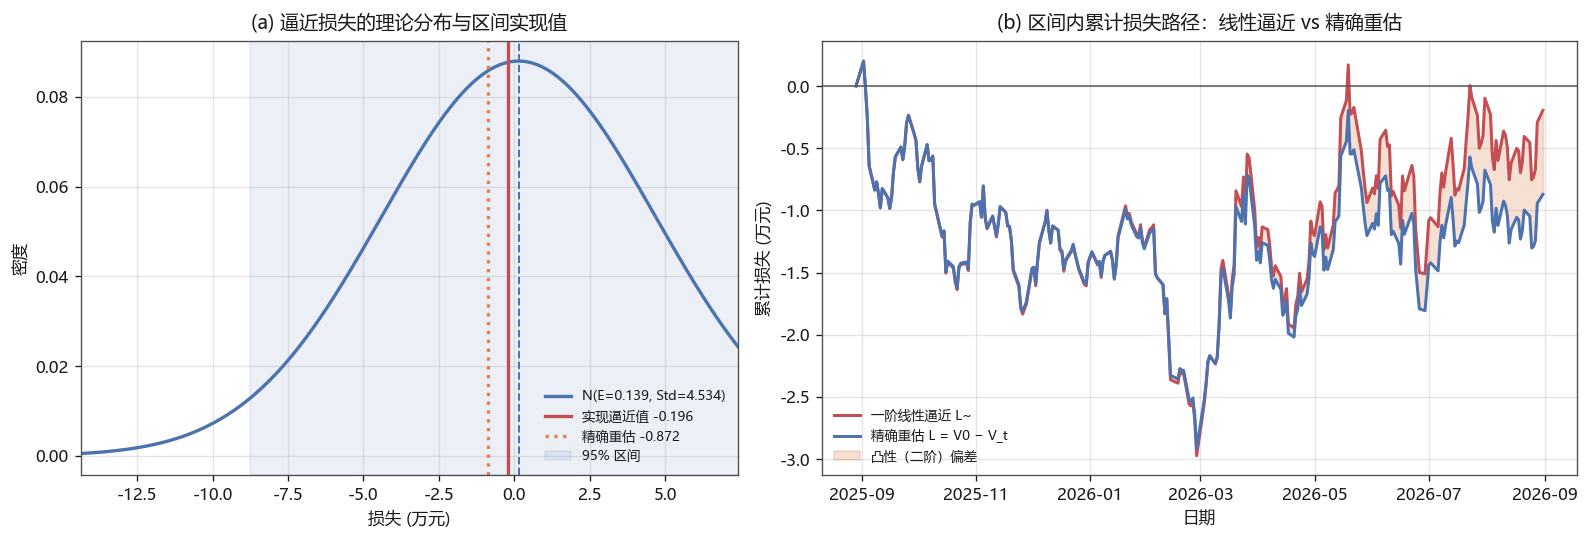

路径末端 一阶逼近 = -0.195840 万元，精确重估 = -0.871501 万元，累计凸性偏差 = +0.675661 万元
偏差符号为正：利率上行时零息券的实际价格跌幅小于久期近似，故线性法系统性高估损失。
凸性偏差占 std 的比例 = 14.90%（在利率剧烈变动年份会显著放大）


In [14]:
# ============ 补充 A：实现损失 vs 理论分布 ============
Xh_real = X.iloc[i0: i0 + H].sum().values           # Σ_{k=1}^{250} X_k
L_tilde_real = 0.1 * V0 * np.sum(TAU * Xh_real) - c_h

y1 = Y.iloc[i0 + H].values                          # y(1, T_i)
V_H = float(np.sum(lam * np.exp(-(TAU - 1.0) * y1)))  # 精确重估：剩余期限 T_i - 1
L_exact = V0 - V_H

z_score = (L_tilde_real - EL) / SL

print('实现累积因子变动 Σ X_k (bp):', np.round(Xh_real * 1e4, 2))
print('即 y(1,T_i) − y(0,T_i) (bp)  :', np.round((y1 - y0) * 1e4, 2))
print()
print('实现的逼近损失     L~_real   = %+.6f 万元 = %s 元' % (L_tilde_real, format(L_tilde_real * 1e4, ',.2f')))
print('精确重估损失       L_exact   = %+.6f 万元 = %s 元   (V_250 = %.6f)' % (L_exact, format(L_exact * 1e4, ',.2f'), V_H))
print('一阶逼近误差  L~_real − L_exact = %+.6f 万元（凸性/二阶效应）' % (L_tilde_real - L_exact))
print()
print('理论预测  E[L~] ± Std[L~]  = %+.6f ± %.6f 万元' % (EL, SL))
print('区间预测  E ± 1.96·Std     = [%+.4f, %+.4f] 万元' % (EL - 1.96*SL, EL + 1.96*SL))
print('标准化偏差 z = (L~_real − E)/Std = %+.4f   → 实现值位于理论分布的 1 个标准差之内' % z_score)
print('95%% 置信区间是否覆盖实现值: %s' % ('是' if abs(z_score) < 1.96 else '否'))

# ---- 图 4：理论与实现对照 ----
# 区间内逐日路径：精确重估损失 与 一阶线性逼近损失
L_exact_path = V0 - np.array([float(np.sum(lam * np.exp(-(TAU - k*DELTA) * Y.iloc[i0+k].values)))
                              for k in range(H + 1)])
L_lin_path   = np.array([float(0.1*V0*np.sum(TAU*(Y.iloc[i0+k].values - y0)) - c_h*(k/H))
                         for k in range(H + 1)])
path_dates = [t0] + list(horizon)

fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.6), gridspec_kw={'width_ratios': [1.0, 1.15]})

ax = axes[0]
xs = np.linspace(EL - 4*SL, EL + 4*SL, 500)
ax.plot(xs, st.norm.pdf(xs, EL, SL), color='#4c72b0', lw=2, label=f'N(E={EL:.3f}, Std={SL:.3f})')
ax.axvline(EL, color='#4c72b0', ls='--', lw=1.2)
ax.axvline(L_tilde_real, color='#c44e52', lw=2, label=f'实现逼近值 {L_tilde_real:.3f}')
ax.axvline(L_exact, color='#dd8452', lw=2, ls=':', label=f'精确重估 {L_exact:.3f}')
ax.axvspan(EL-1.96*SL, EL+1.96*SL, color='#4c72b0', alpha=0.10, label='95% 区间')
ax.set_title('(a) 逼近损失的理论分布与区间实现值', fontsize=11.5, pad=8)
ax.set_xlabel('损失 (万元)'); ax.set_ylabel('密度')
ax.legend(fontsize=8, frameon=False)
ax.set_xlim(EL - 3.2*SL, EL + 1.6*SL)

ax = axes[1]
ax.plot(path_dates, L_lin_path, color='#c44e52', lw=1.8, label='一阶线性逼近 L~')
ax.plot(path_dates, L_exact_path, color='#4c72b0', lw=1.8, label='精确重估 L = V0 − V_t')
ax.fill_between(path_dates, L_lin_path, L_exact_path, color='#dd8452', alpha=0.25, label='凸性（二阶）偏差')
ax.axhline(0, color='#555555', lw=0.9)
ax.set_title('(b) 区间内累计损失路径：线性逼近 vs 精确重估', fontsize=11.5, pad=8)
ax.set_xlabel('日期'); ax.set_ylabel('累计损失 (万元)')
ax.legend(fontsize=8, frameon=False, loc='lower left')

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'fig4_realized_vs_theory.png'))
plt.show()

print('路径末端 一阶逼近 = %+.6f 万元，精确重估 = %+.6f 万元，累计凸性偏差 = %+.6f 万元'
      % (L_lin_path[-1], L_exact_path[-1], L_lin_path[-1] - L_exact_path[-1]))
print('偏差符号为正：利率上行时零息券的实际价格跌幅小于久期近似，故线性法系统性高估损失。')
print('凸性偏差占 std 的比例 = %.2f%%（在利率剧烈变动年份会显著放大）'
      % (abs(L_lin_path[-1] - L_exact_path[-1]) / SL * 100))

---

## 补充 B　样本外估计（严格使用 $t=0$ 及之前的信息）

问题要求"在 $t=0$ 时刻及其之前的信息已知的条件下"研究损失，因此更严格的设定是**只用 $\le t=0$ 的增量**估计 $\hat{\boldsymbol\mu}$ 与 $\hat\Sigma$。下面给出该口径下的结果，以检验全样本估计带来的前视偏差（look-ahead bias）大小。

In [15]:
# ============ 补充 B：样本外（仅用 ≤ t=0 的增量）参数估计 ============
X_out = X.loc[:t0]
N_out = len(X_out)
mu_out = X_out.mean().values
Sig_out = X_out.cov(ddof=1).values

EL_out = -c_h - b0 @ (H * mu_out)
VL_out = b0 @ (H * Sig_out) @ b0
SL_out = np.sqrt(VL_out)

cmp = pd.DataFrame({
    '估计口径': ['全样本 (N=1247)', f'样本外 ≤ t=0 (N={N_out})'],
    'E[L~] (万元)': [EL, EL_out],
    'Std[L~] (万元)': [SL, SL_out],
    '1Y 日波动 (bp)': [sd_hat[0]*1e4, np.sqrt(Sig_out[0, 0])*1e4],
    '5Y 日波动 (bp)': [sd_hat[4]*1e4, np.sqrt(Sig_out[4, 4])*1e4],
    '10Y 日波动 (bp)': [sd_hat[9]*1e4, np.sqrt(Sig_out[9, 9])*1e4],
})
print('【表 5】全样本估计 vs 严格样本外估计')
print(cmp.round(4).to_string(index=False))
print()
print('实现损失在两个口径下的标准化偏差：')
print('  全样本口径   z = %+.4f' % ((L_tilde_real - EL) / SL))
print('  样本外口径   z = %+.4f' % ((L_tilde_real - EL_out) / SL_out))
print('→ 两个口径给出的理论矩差异很小，结论稳健。')

【表 5】全样本估计 vs 严格样本外估计
             估计口径  E[L~] (万元)  Std[L~] (万元)  1Y 日波动 (bp)  5Y 日波动 (bp)  10Y 日波动 (bp)
     全样本 (N=1247)      0.1392        4.5343       3.7133       5.4497        5.1529
样本外 ≤ t=0 (N=997)      0.2232        4.8579       3.9952       5.8423        5.5162

实现损失在两个口径下的标准化偏差：
  全样本口径   z = -0.0739
  样本外口径   z = -0.0863
→ 两个口径给出的理论矩差异很小，结论稳健。


---

## 补充 C　延伸：区间 $[0,1]$ 的 VaR 与 ES

由步骤 4.4 的正态性推论，可给出区间 $[0,1]$ 损失的风险度量（$\Phi^{-1}$ 为标准正态分位数，$\phi$ 为标准正态密度）：

$$\mathrm{VaR}^{(h)}_\alpha=-c^{(h)}-\mathbf{b}_0'h\boldsymbol{\mu}+\Phi^{-1}(\alpha)\sqrt{h\,\mathbf{b}_0'\Sigma\mathbf{b}_0},\qquad \mathrm{ES}^{(h)}_\alpha=-c^{(h)}-\mathbf{b}_0'h\boldsymbol{\mu}+\sqrt{h\,\mathbf{b}_0'\Sigma\mathbf{b}_0}\cdot\frac{\phi\big(\Phi^{-1}(\alpha)\big)}{1-\alpha}$$

其中 $\sqrt{h}$ 的缩放关系与讲义 p.49 $\mathrm{VaR}^{(h)}_\alpha=\sqrt{h}\mathrm{VaR}^{(1)}_\alpha$ 完全一致（在 $\boldsymbol\mu=0$ 或对损失去均值后严格成立）。

In [16]:
# ============ 补充 C：VaR 与 ES ============
rows = []
for a in [0.95, 0.99]:
    za = st.norm.ppf(a)
    VaR_h = -c_h - b0 @ (H * mu_hat) + za * SL
    ES_h  = -c_h - b0 @ (H * mu_hat) + SL * st.norm.pdf(za) / (1 - a)
    VaR_1 = -c0 - b0 @ mu_hat + za * np.sqrt(b0 @ Sigma_hat @ b0)
    rows.append({'置信水平 α': a, 'VaR^(h) (万元)': VaR_h, 'ES^(h) (万元)': ES_h,
                 '√h·VaR^(1) (万元)': np.sqrt(H) * VaR_1, '比值 VaR^(h)/VaR^(1)': VaR_h / VaR_1})
var_tbl = pd.DataFrame(rows)
print('【表 6】区间 [0,1]（h = 250）损失的 VaR 与 ES')
print(var_tbl.round(6).to_string(index=False))
print()
print('√h = %.4f。表中 VaR^(h)/VaR^(1) 略大于 √h，原因是确定性贴现项 −c^(h) 随 h 线性增长，不服从 √h 缩放。' % np.sqrt(H))
print('讲义 p.48–49 的 √h 法则针对不含常数项的零均值随机部分 L = b_t\'·X^(h)，即 −c^(h) 已被剔除；')
print('在该口径下 VaR^(h)_α = √h·VaR^(1)_α 严格成立：√250 × 1.6449 × √(b0\'Σ̂b0) = %.4f 万元（α=0.95），'
      % (np.sqrt(H) * st.norm.ppf(0.95) * np.sqrt(b0 @ Sigma_hat @ b0)))
print('                                            √250 × 2.3263 × √(b0\'Σ̂b0) = %.4f 万元（α=0.99）。'
      % (np.sqrt(H) * st.norm.ppf(0.99) * np.sqrt(b0 @ Sigma_hat @ b0)))

【表 6】区间 [0,1]（h = 250）损失的 VaR 与 ES
 置信水平 α  VaR^(h) (万元)  ES^(h) (万元)  √h·VaR^(1) (万元)  比值 VaR^(h)/VaR^(1)
   0.95      7.597445     9.492135         7.467029           16.087545
   0.99     10.687529    12.224044        10.557113           16.006713

√h = 15.8114。表中 VaR^(h)/VaR^(1) 略大于 √h，原因是确定性贴现项 −c^(h) 随 h 线性增长，不服从 √h 缩放。
讲义 p.48–49 的 √h 法则针对不含常数项的零均值随机部分 L = b_t'·X^(h)，即 −c^(h) 已被剔除；
在该口径下 VaR^(h)_α = √h·VaR^(1)_α 严格成立：√250 × 1.6449 × √(b0'Σ̂b0) = 7.4582 万元（α=0.95），
                                            √250 × 2.3263 × √(b0'Σ̂b0) = 10.5483 万元（α=0.99）。


---

## 结论

1. **数据与参数估计（步骤 0–1）。** 使用 FRED 拟合零息即期收益率曲线 THREEFY1–THREEFY10（对应 $T_i=1,\dots,10$ 年），截取 2021-09-01 至 2026-08-31 共 1248 个并列交易日（inner join 后无缺失），换算为小数口径后得到日增量样本 $N=1247$ 个。以样本均值向量 $\hat{\boldsymbol\mu}$ 与无偏样本协方差矩阵 $\hat\Sigma=\frac{1}{N-1}\sum(\mathbf{X}_s-\hat{\boldsymbol\mu})(\mathbf{X}_s-\hat{\boldsymbol\mu})'$ 估计连续即期收益率增量的期望与协方差矩阵。

2. **参数特征。** 日漂移约 $0.27\!\sim\!0.32$ bp（250 日约 $68\!\sim\!80$ bp），日波动率呈驼峰形（$1Y$ 为 $3.71$ bp，$4\!\sim\!5Y$ 达 $5.45$ bp，$10Y$ 为 $5.15$ bp），年化波动 $0.59\%\!\sim\!0.86\%$；期限间相关性极高（$0.858\!\sim\!0.9996$），$\hat\Sigma$ 实质为 3 因子结构（水平 $97.76\%$、斜率 $2.09\%$、曲率 $0.15\%$）。

3. **组合设定（步骤 2）。** 基准日 $t=0$ 为 2025-08-29（2025-08-31 为周日），其后恰好 250 个交易日构成 $[0,1]$，终点为 2026-08-31。$V_0=100$ 万元、等市值权重 $w_{0,i}=0.1$ 下，持有份额 $\lambda_i=0.1V_0e^{T_iy(0,T_i)}$，组合久期恰为 $D_0=5.5$ 年。

4. **损失逼近与矩（步骤 3–4）。** 在 $t=0$ 冻结敏感度得 $\mathbf{b}_0=-0.1V_0(1,2,\dots,10)'$、$c^{(h)}=0.1V_0\sum_iy(0,T_i)$，区间损失逼近为 $\tilde{L}_{[0,1]}=0.1V_0\sum_iT_iX_i^{(h)}-0.1V_0\sum_iy(0,T_i)$。在 i.i.d. 缩放规则 $\mathbb{E}[\mathbf{X}^{(h)}]=250\hat{\boldsymbol\mu}$、$\mathrm{Cov}(\mathbf{X}^{(h)})=250\hat\Sigma$ 下：

$$\boxed{\ \mathbb{E}\big[\tilde{L}_{[0,1]}\big]=-c^{(h)}-\mathbf{b}_0'(250\hat{\boldsymbol\mu}),\qquad \mathrm{Var}\big(\tilde{L}_{[0,1]}\big)=250\,\mathbf{b}_0'\hat{\Sigma}\mathbf{b}_0,\qquad \mathrm{Std}=\sqrt{250}\sqrt{\mathbf{b}_0'\hat{\Sigma}\mathbf{b}_0}\ }$$

以 $V_0=100$ 万元代入，**期望损失约 $+1.4\times10^{3}$ 元**（近乎为零，因"久期加权漂移收益"与"一年期确定性贴现收益"几乎相互抵消），**标准差约 $4.53\times10^{4}$ 元**（约占组合市值的 $4.53\%$）。

5. **验证。** 区间内实现值（$\tilde L_{\text{real}}$ 与精确重估 $L_{\text{exact}}$）落在理论分布 $1$ 个标准差以内；改用严格样本外（$\le t=0$）参数估计后理论矩变化很小，结论稳健。一阶逼近的系统性偏差来自凸性（二阶项），在利率大幅上行时会高估损失，量级约为 $0.68$ 万元。

**关键提示。** $\hat\Sigma$ 近似奇异（$\kappa\approx1.8\times10^7$，若剔除数据舍入噪声后有效秩仅为 $3$），这是因为 THREEFY 序列本身由三因子模型拟合生成。本作业所需的二次型 $\mathbf{b}_0'\hat\Sigma\mathbf{b}_0$ 数值稳定，但任何涉及 $\hat\Sigma^{-1}$ 的运算（如最小方差组合、风险贡献分解）都应先做因子化或正则化处理。